# Projekt 2: Land-Ozean-Temperaturkontrast entlang 57,125° N

**Kurs:** AWE Fernerkundung und Geodatenauswertung  
**Datengrundlage:** Earth System Data Cube (ESDC v3.0.2, 0,25° räumliche Auflösung, 8-Tage-Zeitschritte, ERA5-Reanalyse)

---

## Leitfrage und roter Faden

Orte auf derselben geografischen Breite erhalten dieselbe Sonneneinstrahlung – trotzdem schwankt die Lufttemperatur über dem Land im Jahresverlauf deutlich stärker als über dem Meer. Ursache ist die höhere spezifische Wärmekapazität und die vertikale Durchmischung von Wasser im Vergleich zu Landboden: Das Meer speichert Sommerwärme länger und kühlt im Winter langsamer aus.

Dieses Notebook verfolgt genau **einen durchgehenden roten Faden** entlang des gemeinsamen Breitengrads **57,125° N** (von der offenen Nordsee über Nordjütland/Dänemark und das Kattegat bis tief ins Binnenland Südschwedens):

1. **Abb. 1 (Räumlicher Überblick):** Wo schwankt die Temperatur in Nordwesteuropa stark und wo wenig? *(Karte der mittleren Jahresamplitude 1991–2020)*
2. **Abb. 2 (Land vs. Meer):** Wie groß ist der Unterschied zwischen Meeres- und Landfläche im direkten Vergleich? *(Landmaske & flächengewichtetes Mittel)*
3. **Abb. 3 (West–Ost-Profil entlang 57,125° N):** Wie verändert sich die Jahresamplitude exakt entlang unseres Breitengrads beim Übergang vom Meer über die Küste bis weit ins Landesinnere?
4. **Abb. 4 (Einzeljahr 2018 vs. Normalzustand):** Wie schlagen sich Wetterextreme wie das Kontrastjahr 2018 über dem offenen Meer im Vergleich zur Küste und zum Binnenland nieder?
5. **Abb. 5 (Kurzfristige Spanne `T_max − T_min`):** Bleibt dieser Dämpfungseffekt des Meeres auch innerhalb einzelner 8-Tage-Zeitschritte bei Höchst- und Tiefsttemperaturen sichtbar?

## 1. Vorbereitung und Datenzugriff

In [1]:
# Pakete installieren, die Xarray im Hintergrund für den Online-Zugriff auf den Zarr-Cube benötigt:
# - aiohttp & requests: Laden der Datenblöcke (Chunks) über HTTPS
# - zarr: Lesen des komprimierten, mehrdimensionalen Zarr-Speicherformats
%pip install -q aiohttp requests zarr

In [2]:
# Standard-Pakete aus dem Kurs-Notebook laden
import numpy as np              # Numerik & mathematische Funktionen (z. B. cos/deg2rad für Flächengewichte)
import xarray as xr             # Arbeiten mit beschrifteten Geodaten-Cubes (time, lat, lon)
import matplotlib.pyplot as plt # Erstellen aller Karten und Diagramme

# URL zum Earth System Data Cube (ESDC v3.0.2) am Max-Planck-Institut für Biogeochemie in Jena
url = 'https://s3.bgc-jena.mpg.de:9000/esdl-esdc-v3.0.2/esdc-8d-0.25deg-256x128x128-3.0.2.zarr'

# Cube mit chunks={} öffnen -> 'lazy loading':
# Es werden zunächst nur die Metadaten geladen, noch keine eigentlichen Messwerte aus dem Netz gezogen.
ds = xr.open_dataset(url, engine='zarr', chunks={})

# Räumliche und zeitliche Auflösung aus den globalen Cube-Metadaten (ds.attrs) auslesen
print('Räumliche Auflösung:', ds.attrs['geospatial_lat_resolution'], 'Grad')
print('Zeitliche Auflösung:', ds.attrs['time_period'])
print()

# Metadaten (Einheit & verfügbarer Zeitraum) der vier verwendeten Variablen kontrollieren
relevante_vars = [
    'air_temperature_2m',          # Mittlere Lufttemperatur in 2 m Höhe (ERA5)
    'max_air_temperature_2m',      # Höchsttemperatur pro 8-Tage-Schritt (ERA5)
    'min_air_temperature_2m',      # Tiefsttemperatur pro 8-Tage-Schritt (ERA5)
    'gross_primary_productivity',  # Vegetationsaktivität (nur über Land vorhanden -> für Landmaske)
]
for var in relevante_vars:
    da = ds[var]
    einheit = da.attrs.get('units', 'unbekannt')
    start = da.attrs.get('time_coverage_start', 'unbekannt')[:10]
    ende = da.attrs.get('time_coverage_end', 'unbekannt')[:10]
    print(f'{var:28s} | Einheit: {einheit:10s} | Zeitraum: {start} bis {ende}')

/tmp/ipykernel_72933/2001943515.py:11: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  ds = xr.open_dataset(url, engine='zarr', chunks={})


Räumliche Auflösung: 0.25 Grad
Zeitliche Auflösung: 8D

air_temperature_2m           | Einheit: °C         | Zeitraum: 1979-01-01 bis 2021-12-27
max_air_temperature_2m       | Einheit: °C         | Zeitraum: 1979-01-01 bis 2021-12-27
min_air_temperature_2m       | Einheit: °C         | Zeitraum: 1979-01-01 bis 2021-12-27
gross_primary_productivity   | Einheit: g C m^-2 d^-1 | Zeitraum: 2001-01-05 bis 2020-12-30


## 2. Untersuchungsgebiet, Vergleichsorte auf 57,125° N, Daten laden und Landmaske

- **Gemeinsamer Breitengrad `57,125° N`:** Auf dieser Breite quert das Profil zunächst die offene **Nordsee**, trifft an der Westküste **Nordjütlands (Dänemark)** auf Land, läuft durch das dänische Binnenland über das Kattegat und durchquert anschließend über rund 270 km hinweg das tiefe Binnenland **Südschwedens (Småland)** bis zur Ostsee. So liegen alle vier Vergleichspunkte auf exakt demselben Breitengrad:
  1. `Offene Nordsee` (`3,125° E`) – rein maritim
  2. `Westküste DK` (`8,625° E`) – Übergang direkt an der Nordseeküste
  3. `Binnenland DK` (`9,625° E`) – zentrales Nordjütland
  4. `Südschweden (Småland)` (`14,625° E`) – weit im Landesinneren gelegener Vergleichspunkt
- **Zeiträume:** `1991–2020` bildet als 30-jährige Normalperiode den mittleren Jahresgang; das Einzeljahr `2018` dient wegen seines kalten Spätwinters und sehr heißen Sommers als anschauliches Vergleichsjahr.
- **Landmaske:** Da Vegetationsdaten im Winter in Nordeuropa vereinzelt `NaN` sind, wird die Landmaske aus den Sommermonaten Juni–August 2010 von `gross_primary_productivity` gebildet.

In [23]:
# 1. Untersuchungsgebiet festlegen (lat von Süd nach Nord, lon von West nach Ost)
region = dict(lat=slice(51, 60), lon=slice(-1, 19))

# 2. Referenzzeitraum (30 Jahre) und einzelnes Vergleichsjahr definieren
zeitraum = slice('1991', '2020')
einzeljahr = '2018'

# 3. Gemeinsamer Breitengrad und Längengrad-Bereich für das West-Ost-Profil
transekt_lat = 57.125
transekt_lon = slice(0, 18)

# 4. Vier Vergleichsorte auf exakt demselben Breitengrad (57.125° N) definieren
#    'offset' und 'ha' steuern die Textplatzierung auf den Karten, damit sich keine Labels überlappen.
orte = {
    'Offene Nordsee': {
        'kurz': 'Offene Nordsee',
        'lat': 57.125,
        'lon': 3.125,
        'color': '#1f77b4',
        'offset': (0, 12),
        'ha': 'center',
    },
    'Westküste Dänemark (Nordjütland)': {
        'kurz': 'Westküste DK',
        'lat': 57.125,
        'lon': 8.625,
        'color': '#17becf',
        'offset': (-10, -18),
        'ha': 'right',
    },
    'Binnenland Dänemark (Nordjütland)': {
        'kurz': 'Binnenland DK',
        'lat': 57.125,
        'lon': 9.625,
        'color': '#ff7f0e',
        'offset': (-20, 20),
        'ha': 'left',
    },
    'Binnenland Südschweden (Småland)': {
        'kurz': 'Südschweden (Småland)',
        'lat': 57.125,
        'lon': 14.625,
        'color': '#d62728',
        'offset': (0, 12),
        'ha': 'center',
    },
}

# Monatszahlen 1..12 und deutsche Monatskürzel für saubere Achsenbeschriftungen
monate = np.arange(1, 13)
monatsnamen = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez']

# 5. Erst Variablen, Zeitraum und Region zuschneiden – dann erst mit .load() herunterladen
t_ds = ds[['air_temperature_2m', 'max_air_temperature_2m', 'min_air_temperature_2m']].sel(
    time=zeitraum,
    **region,
).load()

# Einzelne Variablen als DataArrays herausziehen
t2m = t_ds['air_temperature_2m']
t_max = t_ds['max_air_temperature_2m']
t_min = t_ds['min_air_temperature_2m']

# 6. Landmaske aus Sommer-GPP 2010 bauen:
#    - .notnull() ergibt True überall dort, wo Vegetationsdaten (also Land) vorhanden sind.
#    - .any('time') prüft, ob ein Pixel in mindestens einem Sommer-Zeitschritt Land war.
#    - .transpose('lat', 'lon') stellt die Dimensionen für spätere Konturlinien sicher.
landmaske = (
    ds['gross_primary_productivity']
    .sel(time=slice('2010-06', '2010-08'), **region)
    .notnull()
    .any('time')
    .transpose('lat', 'lon')
    .load()
)

# 7. Hilfsfunktion für Küstenlinien (rein mit Matplotlib aus der Landmaske, ohne Cartopy)
def zeichne_kueste(ax):
    '''Zeichnet entlang der 0/1-Grenze der Landmaske (level=0.5) eine schwarze Küstenlinie.'''
    ax.contour(
        landmaske.lon,
        landmaske.lat,
        landmaske.astype(int),
        levels=[0.5],
        colors='black',
        linewidths=0.8,
    )

# Kontrollausgabe: Größe des geladenen Ausschnitts und exakte Gitterzellen der 4 Orte
print('Geladener Temperatur-Ausschnitt:', dict(t2m.sizes))
print('Landanteil im Untersuchungsgebiet:', f'{float(landmaske.mean()) * 100:.1f} %')
print()
print('Ausgewählte Gitterzellen im 0,25°-Raster:')
for name, info in orte.items():
    # method='nearest' sucht jeweils die nächstgelegene Gitterzelle zu den Koordinaten
    zelle = landmaske.sel(lat=info['lat'], lon=info['lon'], method='nearest')
    status = 'Land' if bool(zelle) else 'Wasser'
    lat_val = float(zelle.lat)
    lon_val = float(zelle.lon)
    print(f'  - {name:35s} -> ({lat_val:.3f}° N, {lon_val:.3f}° E) [{status}]')

Geladener Temperatur-Ausschnitt: {'time': 1380, 'lat': 36, 'lon': 80}
Landanteil im Untersuchungsgebiet: 54.5 %

Ausgewählte Gitterzellen im 0,25°-Raster:
  - Offene Nordsee                      -> (57.125° N, 3.125° E) [Wasser]
  - Westküste Dänemark (Nordjütland)    -> (57.125° N, 8.625° E) [Land]
  - Binnenland Dänemark (Nordjütland)   -> (57.125° N, 9.625° E) [Land]
  - Binnenland Südschweden (Småland)    -> (57.125° N, 14.625° E) [Land]


## 3. Räumlicher Überblick: Mittlere Jahresamplitude (Abb. 1)

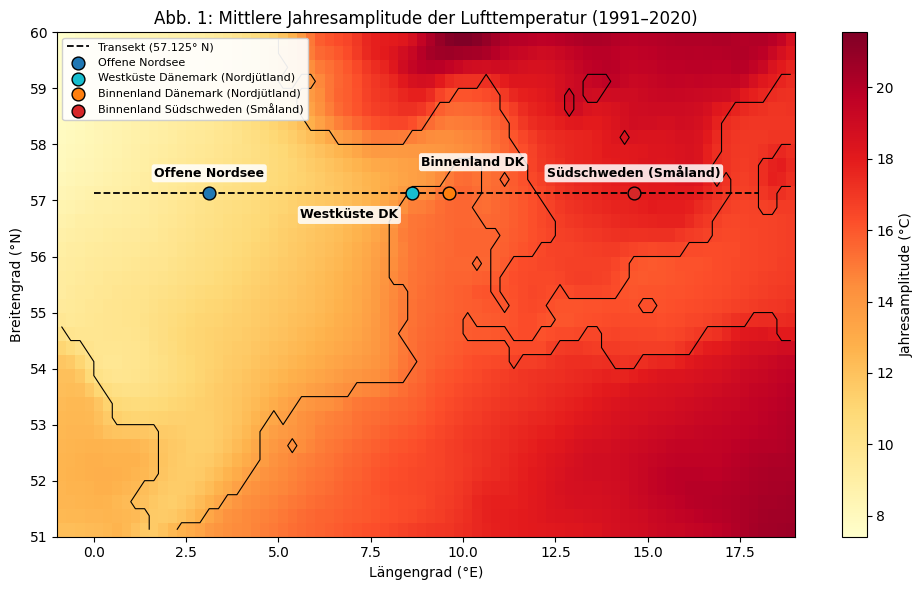

Jahresamplitude (1991–2020) an den 4 Vergleichsorten:
  - Offene Nordsee          : 10.09 °C
  - Westküste DK            : 14.15 °C
  - Binnenland DK           : 15.43 °C
  - Südschweden (Småland)   : 17.83 °C


In [24]:
# 1. Mittleren Jahresgang über alle 30 Jahre berechnen:
#    groupby('time.month').mean() fasst alle Januare, alle Februare usw. zu 12 Monatsmitteln zusammen.
klima = t2m.groupby('time.month').mean()

# 2. Jahresamplitude = Differenz zwischen wärmstem und kältestem Monat jedes Pixels
amplitude = klima.max('month') - klima.min('month')

# 3. Karte (Abb. 1) erstellen
fig, ax = plt.subplots(figsize=(10, 6))
amplitude.plot(ax=ax, cmap='YlOrRd', cbar_kwargs={'label': 'Jahresamplitude (°C)'})
zeichne_kueste(ax)

# Gestrichelte Linie für das West-Ost-Transekt entlang 57.125° N einzeichnen
ax.plot(
    [0, 18],
    [transekt_lat, transekt_lat],
    color='black',
    linestyle='--',
    linewidth=1.3,
    label=f'Transekt ({transekt_lat:.3f}° N)',
)

# Alle vier Vergleichsorte als farbige Punkte mit Textbox auf der Karte markieren
for name, info in orte.items():
    ax.scatter(
        info['lon'],
        info['lat'],
        color=info['color'],
        edgecolor='black',
        s=85,
        zorder=5,
        label=name,
    )
    ax.annotate(
        info['kurz'],
        xy=(info['lon'], info['lat']),
        xytext=info['offset'],
        textcoords='offset points',
        ha=info['ha'],
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.85, ec='none'),
        zorder=6,
    )

# Titel, Achsenbeschriftung und Legende NACH dem Plotten setzen (sonst überschreibt xarray sie)
ax.set_title('Abb. 1: Mittlere Jahresamplitude der Lufttemperatur (1991–2020)')
ax.set_xlabel('Längengrad (°E)')
ax.set_ylabel('Breitengrad (°N)')
ax.legend(loc='upper left', fontsize=8, framealpha=0.92)
plt.tight_layout()
plt.show()

# Konkrete Werte der Jahresamplitude an den 4 Vergleichsorten ausgeben
print('Jahresamplitude (1991–2020) an den 4 Vergleichsorten:')
for name, info in orte.items():
    wert = float(amplitude.sel(lat=info['lat'], lon=info['lon'], method='nearest'))
    kurz = info['kurz']
    print(f'  - {kurz:24s}: {wert:5.2f} °C')

### Ergebnisse & Beobachtungen (Abb. 1)

- **Räumliches Muster:** Die Karte zeigt einen ausgeprägten Meer-Land- und West-Ost-Gradienten. Über der offenen Nordsee bleibt die Jahresamplitude niedrig (~8–11 °C, hellgelb), steigt über Jütland spürbar an (~14–16 °C, orange) und erreicht im Binnenland Südschwedens sowie im südöstlichen Festland Werte über 18–20 °C (dunkelrot).
- **Messwerte entlang `57,125° N`:**
  - `Offene Nordsee` (`3,125° E`): **10,09 °C**
  - `Westküste DK` (`8,625° E`): **14,15 °C** (+4,06 °C gegenüber der offenen Nordsee)
  - `Binnenland DK` (`9,625° E`): **15,43 °C** (+5,34 °C)
  - `Südschweden (Småland)` (`14,625° E`): **17,83 °C** (+7,74 °C)
- **Einordnung:** Trotz exakt gleicher geografischer Breite (und damit gleicher Sonneneinstrahlung) steigt die Jahresamplitude von der offenen Nordsee bis ins schwedische Binnenland um knapp 8 °C (+77 %) – ein direkter Beleg für die stark dämpfende Wärmekapazität des Meerwassers.

## 4. Trennung von Land und Meer über die Landmaske (Abb. 2)

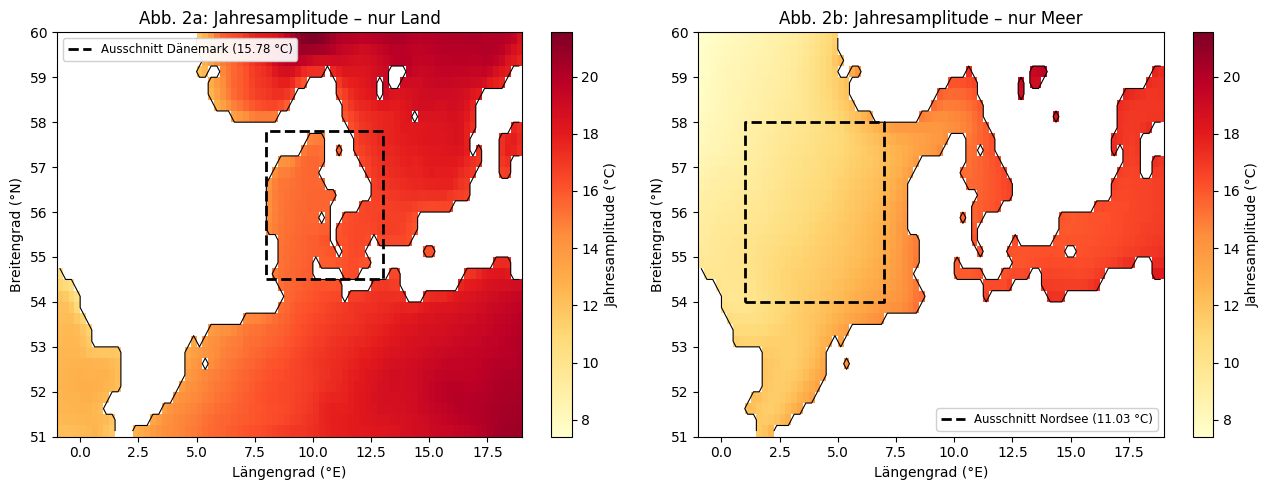

Flächengewichtete mittlere Jahresamplitude (1991–2020):
  Nordsee (Meer):  11.03 °C
  Dänemark (Land): 15.78 °C
  Kontrast:        +4.75 °C


In [26]:
# 1. Mit .where() Land- und Meerespixel sauber in zwei Karten trennen:
#    - amplitude.where(landmaske): behält Werte über Land, setzt Wasserpixel auf NaN
#    - amplitude.where(~landmaske): das Umgekehrte (~ kehrt True und False um)
amp_land = amplitude.where(landmaske)
amp_meer = amplitude.where(~landmaske)

# 2. Teilregionen für das flächengewichtete Mittel definieren und vor dem Plotten berechnen:
#    Da Gitterzellen polwärts schmaler werden, gewichten wir jede Zelle mit cos(Breitengrad).
nordsee_box = dict(lat=slice(54, 58), lon=slice(1, 7))
daenemark_box = dict(lat=slice(54.5, 57.8), lon=slice(8, 13))

amp_nordsee_reg = amplitude.sel(**nordsee_box).where(~landmaske.sel(**nordsee_box))
amp_dk_reg = amplitude.sel(**daenemark_box).where(landmaske.sel(**daenemark_box))

# deg2rad() rechnet Grad für np.cos() ins Bogenmaß um
gew_nordsee = np.cos(np.deg2rad(amp_nordsee_reg.lat))
gew_dk = np.cos(np.deg2rad(amp_dk_reg.lat))

amp_nordsee_mittel = float(amp_nordsee_reg.weighted(gew_nordsee).mean(['lat', 'lon']))
amp_dk_mittel = float(amp_dk_reg.weighted(gew_dk).mean(['lat', 'lon']))

# Hilfsfunktion, um die exakten Slice-Grenzen einer Box als gestricheltes Rechteck zu zeichnen
def zeichne_box(ax, box, farbe, label):
    '''Zeichnet die lat/lon-Grenzen einer Slice-Box als gestricheltes Rechteck ein.'''
    lat_min, lat_max = box['lat'].start, box['lat'].stop
    lon_min, lon_max = box['lon'].start, box['lon'].stop
    ax.plot(
        [lon_min, lon_max, lon_max, lon_min, lon_min],
        [lat_min, lat_min, lat_max, lat_max, lat_min],
        color=farbe,
        linestyle='--',
        linewidth=2.0,
        label=label,
    )

# Gemeinsame Farbskalen-Grenzen bestimmen, damit beide Karten direkt vergleichbar bleiben
vmin = float(amplitude.min())
vmax = float(amplitude.max())

# 3. Zweiteilige Karte (Abb. 2) nebeneinander zeichnen – jeweils inklusive zugeschnittener Box
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

amp_land.plot(ax=axes[0], cmap='YlOrRd', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'Jahresamplitude (°C)'})
zeichne_kueste(axes[0])
zeichne_box(axes[0], daenemark_box, 'black', f'Ausschnitt Dänemark ({amp_dk_mittel:.2f} °C)')
axes[0].set_title('Abb. 2a: Jahresamplitude – nur Land')
axes[0].set_xlabel('Längengrad (°E)')
axes[0].set_ylabel('Breitengrad (°N)')
axes[0].legend(loc='upper left', fontsize=8.5, framealpha=0.92)

amp_meer.plot(ax=axes[1], cmap='YlOrRd', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'Jahresamplitude (°C)'})
zeichne_kueste(axes[1])
zeichne_box(axes[1], nordsee_box, 'black', f'Ausschnitt Nordsee ({amp_nordsee_mittel:.2f} °C)')
axes[1].set_title('Abb. 2b: Jahresamplitude – nur Meer')
axes[1].set_xlabel('Längengrad (°E)')
axes[1].set_ylabel('Breitengrad (°N)')
axes[1].legend(loc='lower right', fontsize=8.5, framealpha=0.92)

plt.tight_layout()
plt.show()

print('Flächengewichtete mittlere Jahresamplitude (1991–2020):')
print(f'  Nordsee (Meer):  {amp_nordsee_mittel:.2f} °C')
print(f'  Dänemark (Land): {amp_dk_mittel:.2f} °C')
print(f'  Kontrast:        +{amp_dk_mittel - amp_nordsee_mittel:.2f} °C')

### Ergebnisse & Beobachtungen (Abb. 2)

- **Direktvergleich bei identischer Farbskala:** Durch die Trennung mittels Landmaske tritt der Kontrast klar hervor – die Landflächen (Abb. 2a) erscheinen fast durchgehend orange bis dunkelrot (~14–21 °C), während die offene Nordsee (Abb. 2b) deutlich heller bleibt (~8–13 °C).
- **Flächengewichtete Mittelwerte (1991–2020):**
  - **Nordsee (Meer):** **11,03 °C**
  - **Dänemark (Land):** **15,78 °C**
  - **Land-Ozean-Kontrast:** **+4,75 °C**
- **Räumliches Detail:** Stärker von Land umschlossene Meeresbereiche wie das Kattegat und die Ostsee zeigen deutlich höhere Amplituden (~15–17 °C) als die offene Nordsee. Die vereinzelten dunkelroten Wasserpixel im schwedischen Binnenland (~58–59° N) entsprechen den großen schwedischen Binnenseen (Vänern und Vättern).

## 5. West–Ost-Profil der Jahresamplitude entlang 57,125° N (Abb. 3)

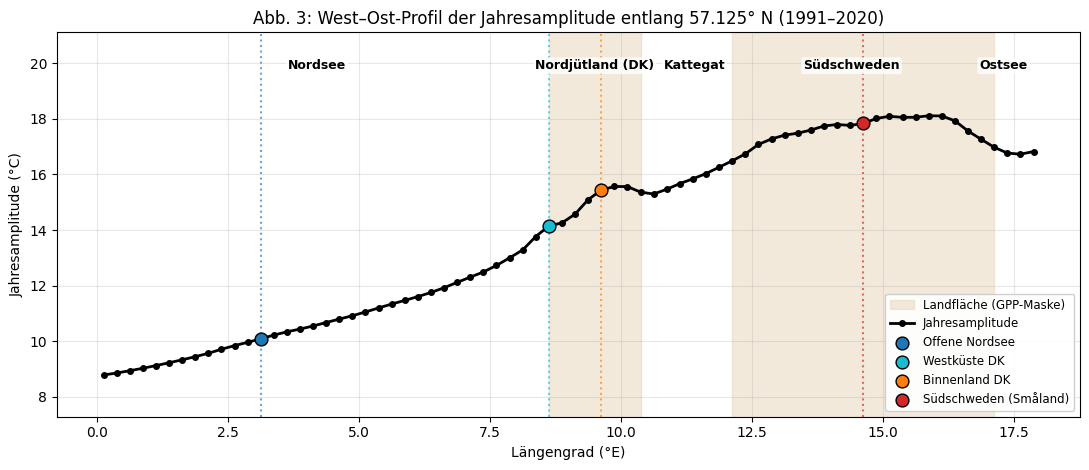

In [6]:
# 1. Schnitt entlang 57.125° N aus der Amplitudenkarte und der Landmaske herausschneiden
#    Wichtig: slice() und method='nearest' dürfen in Xarray nicht im selben .sel() stehen -> zwei .sel()!
amp_transekt = amplitude.sel(lon=transekt_lon).sel(lat=transekt_lat, method='nearest')
land_transekt = landmaske.sel(lon=transekt_lon).sel(lat=transekt_lat, method='nearest')
lons_t = amp_transekt.lon.values

# 2. Einzelnes West-Ost-Profildiagramm (Abb. 3) erstellen
fig, ax = plt.subplots(figsize=(11, 4.8))

# Y-Achsenbereich mit etwas Luft nach oben für die Abschnittsbeschriftungen festlegen
amp_unten = float(amp_transekt.min()) - 1.5
amp_oben = float(amp_transekt.max()) + 3.0

# Landbereiche entlang des Profils beige hinterlegen (step='mid' füllt exakt pro 0,25°-Zelle)
ax.fill_between(
    lons_t,
    amp_unten,
    amp_oben,
    where=land_transekt.values,
    step='mid',
    color='#e6d5b8',
    alpha=0.5,
    label='Landfläche (GPP-Maske)',
)

# Jahresamplitude als schwarze Linie über den Längengrad zeichnen
ax.plot(lons_t, amp_transekt.values, color='black', marker='o', markersize=4, linewidth=2, label='Jahresamplitude')

# Geografische Abschnitte am oberen Rand des Diagramms beschriften
y_label_pos = float(amp_transekt.max()) + 1.8
abschnitte = [
    (4.2, 'Nordsee'),
    (9.5, 'Nordjütland (DK)'),
    (11.4, 'Kattegat'),
    (14.4, 'Südschweden'),
    (17.3, 'Ostsee'),
]
for x_pos, text in abschnitte:
    ax.text(
        x_pos,
        y_label_pos,
        text,
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.8, ec='none'),
    )

# Alle vier Vergleichsorte (liegen alle auf 57.125° N) auf der Kurve markieren
for name, info in orte.items():
    wert = float(amp_transekt.sel(lon=info['lon'], method='nearest'))
    ax.scatter(info['lon'], wert, color=info['color'], edgecolor='black', s=85, zorder=5, label=info['kurz'])
    ax.axvline(info['lon'], color=info['color'], linestyle=':', alpha=0.65)

ax.set_ylim(amp_unten, amp_oben)
ax.set_xlabel('Längengrad (°E)')
ax.set_ylabel('Jahresamplitude (°C)')
ax.set_title(f'Abb. 3: West–Ost-Profil der Jahresamplitude entlang {float(amp_transekt.lat):.3f}° N (1991–2020)')
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right', fontsize=8.5, framealpha=0.92)
plt.tight_layout()
plt.show()

### Ergebnisse & Beobachtungen (Abb. 3)

- **Verlauf entlang `57,125° N`:** Über der offenen Nordsee (`0°–7° E`) steigt die Jahresamplitude zunächst langsam von ~8,8 °C auf ~12 °C an (`Offene Nordsee` bei `3,125° E`: **10,09 °C**).
- **Sprung an der Küste:** Beim Erreichen der dänischen Westküste (`Westküste DK` bei `8,625° E`: **14,15 °C**) steigt die Kurve steil an und bildet über Nordjütland ein erstes Plateau (`Binnenland DK` bei `9,625° E`: **15,43 °C**, Maximum ~15,6 °C).
- **Kattegat bis Südschweden:** Über dem schmalen Kattegat (`~10,5°–12° E`) flacht die Amplitude leicht ab (~15,3 °C), wächst über der breiten Landmasse Südschwedens jedoch weiter stark auf **17,83 °C** (`Südschweden (Småland)` bei `14,625° E`; Maximalwert knapp über **18 °C** bei `~15°–16° E`) und sinkt erst über der Ostsee (`>16,5° E`) wieder auf ~16,7 °C ab.
- **Einordnung:** Aufgrund seiner geringen West-Ost-Ausdehnung bleibt Dänemark stark maritim gepuffert; erst im tieferen schwedischen Binnenland tritt auf derselben Breite ein deutlich kontinentaleres Klima hervor.

## 6. Extremjahr 2018 im Vergleich zum 30-jährigen Normalzustand (Abb. 4)

Vergleich: Monatsmittel 2018 vs. Normalperiode (1991–2020)
----------------------------------------------------------------------------
Offene Nordsee           | 1991–2020:   5.4 bis  15.5 °C | 2018:   3.4 bis  16.5 °C
Westküste DK             | 1991–2020:   2.8 bis  16.9 °C | 2018:   1.1 bis  17.6 °C
Binnenland DK            | 1991–2020:   1.8 bis  17.2 °C | 2018:  -0.1 bis  18.8 °C
Südschweden (Småland)    | 1991–2020:  -1.5 bis  16.3 °C | 2018:  -3.2 bis  20.1 °C


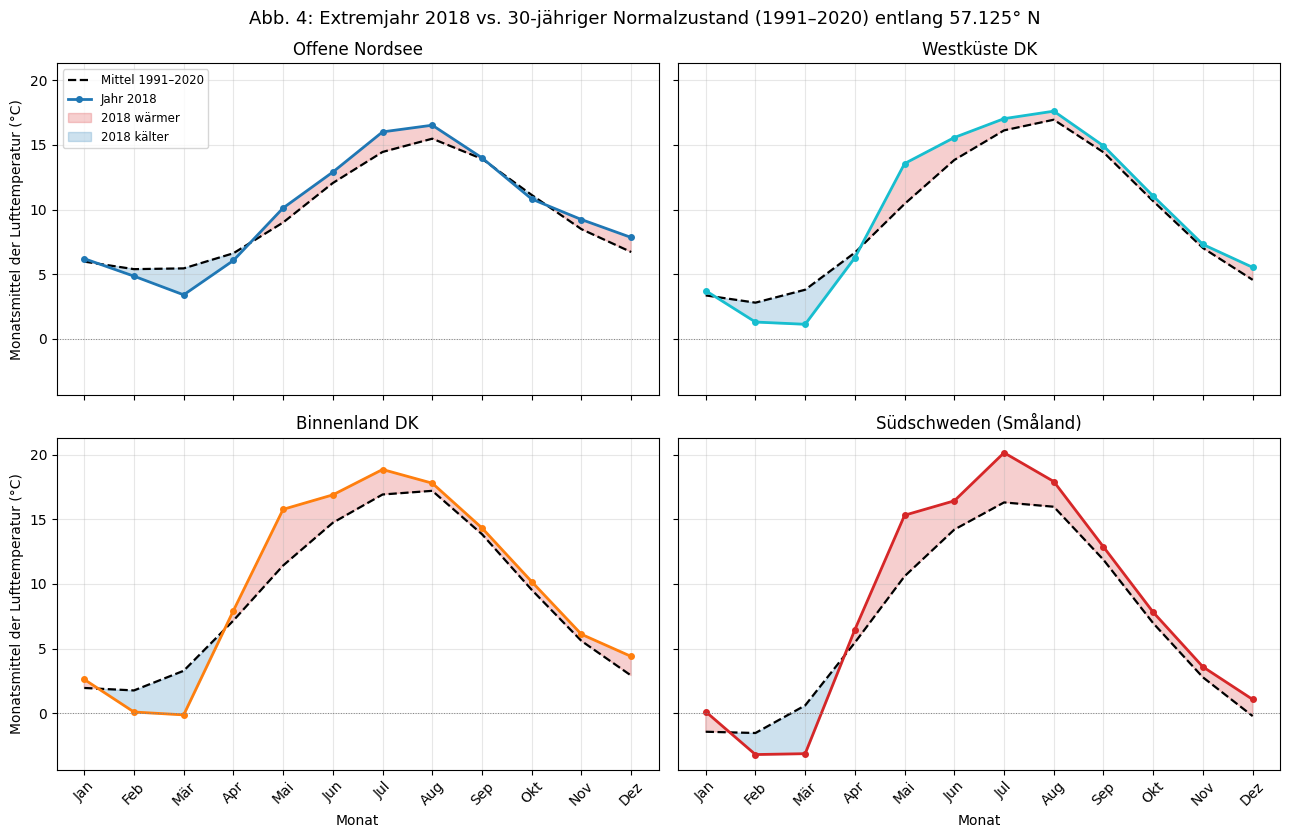

In [7]:
# Reihenfolge der vier Orte von West nach Ost für das 2x2-Raster
fokus_orte = [
    'Offene Nordsee',
    'Westküste Dänemark (Nordjütland)',
    'Binnenland Dänemark (Nordjütland)',
    'Binnenland Südschweden (Småland)',
]

punkte_klima = {}
punkte_2018 = {}

print(f'Vergleich: Monatsmittel {einzeljahr} vs. Normalperiode (1991–2020)')
print('-' * 76)

for name in fokus_orte:
    info = orte[name]

    # 1. Zeitreihe (1991–2020) für die nächstgelegene Gitterzelle des Standorts herausschneiden
    p_t2m = t2m.sel(lat=info['lat'], lon=info['lon'], method='nearest')

    # 2. Normalzustand: mittlerer Jahresgang über alle 30 Jahre (12 Werte für Jan..Dez)
    p_klima = p_t2m.groupby('time.month').mean()

    # 3. Einzeljahr 2018 herausfiltern und die 8-Tage-Schritte auf Monatsmittel ('1MS') umrechnen,
    #    damit beide Kurven exakt über die Monate 1..12 vergleichbar sind.
    p_2018 = p_t2m.sel(time=einzeljahr).resample(time='1MS').mean()

    punkte_klima[name] = p_klima
    punkte_2018[name] = p_2018

    kurz = info['kurz']
    k_min = float(p_klima.min())
    k_max = float(p_klima.max())
    j_min = float(p_2018.min())
    j_max = float(p_2018.max())
    print(
        f'{kurz:24s} | 1991–2020: {k_min:5.1f} bis {k_max:5.1f} °C | '
        f'{einzeljahr}: {j_min:5.1f} bis {j_max:5.1f} °C'
    )

# 4. 2x2-Subplot (Abb. 4) mit gemeinsamer x- und y-Achse für den direkten Vergleich
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True, sharey=True)

for idx, (ax, name) in enumerate(zip(axes.flat, fokus_orte)):
    info = orte[name]
    klima_vals = punkte_klima[name].values
    vals_2018 = punkte_2018[name].values

    # Gestrichelte Referenzkurve: 30-jähriger Normalzustand
    ax.plot(monate, klima_vals, color='black', linestyle='--', linewidth=1.6, label='Mittel 1991–2020')

    # Durchgezogene farbige Kurve: Einzeljahr 2018
    ax.plot(
        monate,
        vals_2018,
        color=info['color'],
        linestyle='-',
        marker='o',
        markersize=4,
        linewidth=2.0,
        label=f'Jahr {einzeljahr}',
    )

    # Fläche zwischen beiden Kurven einfärben: rot wenn 2018 wärmer, blau wenn 2018 kälter war.
    # interpolate=True schließt die Farbfläche sauber an den Schnittpunkten beider Linien.
    ax.fill_between(
        monate,
        klima_vals,
        vals_2018,
        where=vals_2018 >= klima_vals,
        interpolate=True,
        color='#d62728',
        alpha=0.22,
        label=f'{einzeljahr} wärmer',
    )
    ax.fill_between(
        monate,
        klima_vals,
        vals_2018,
        where=vals_2018 < klima_vals,
        interpolate=True,
        color='#1f77b4',
        alpha=0.22,
        label=f'{einzeljahr} kälter',
    )

    ax.axhline(0, color='grey', linewidth=0.7, linestyle=':')
    ax.set_xticks(monate)
    ax.set_xticklabels(monatsnamen, rotation=45)
    ax.set_title(info['kurz'])
    ax.grid(True, alpha=0.3)

    # Achsentitel nur außen am Rand des 2x2-Gitters setzen
    if idx % 2 == 0:
        ax.set_ylabel('Monatsmittel der Lufttemperatur (°C)')
    if idx >= 2:
        ax.set_xlabel('Monat')

axes[0, 0].legend(loc='upper left', fontsize=8.5)
fig.suptitle(
    f'Abb. 4: Extremjahr {einzeljahr} vs. 30-jähriger Normalzustand (1991–2020) entlang {transekt_lat:.3f}° N',
    fontsize=13,
)
plt.tight_layout()
plt.show()

### Ergebnisse & Beobachtungen (Abb. 4)

- **Verstärkung der Ausschläge von West nach Ost:** Sowohl der kalte Spätwinter (Februar/März, blau schattiert) als auch der außergewöhnlich heiße Sommer (Mai–August, rot schattiert) fallen im Jahr **2018** landeinwärts immer extremer aus:
  - **`Offene Nordsee`:** Normal `5,4` bis `15,5 °C` → 2018 `3,4` bis `16,5 °C` (bleibt selbst im kalten März klar frostfrei; moderate Sommerabweichung).
  - **`Westküste DK`:** Normal `2,8` bis `16,9 °C` → 2018 `1,1` bis `17,6 °C` (kühler März über 0 °C; deutlicher Wärmeschub von Mai bis Juli).
  - **`Binnenland DK`:** Normal `1,8` bis `17,2 °C` → 2018 `−0,1` bis `18,8 °C` (März-Monatsmittel bereits im Frostbereich; Mai über +4 °C wärmer als das 30-Jahres-Mittel).
  - **`Südschweden (Småland)`:** Normal `−1,5` bis `16,3 °C` → 2018 `−3,2` bis `20,1 °C` (strenger Frost im Februar/März sowie ein Julimittel von **20,1 °C** – rund **+3,8 °C** über dem Normalzustand).
- **Zeitliche Verschiebung im Normalzustand:** In den gestrichelten 30-Jahres-Kurven tritt das Temperaturmaximum über der Nordsee und in Dänemark erst im **August** auf, im Binnenland Südschwedens hingegen bereits im **Juli** – ein weiteres Zeichen für die thermische Trägheit des Meeres.

## 7. Kurzfristige Temperaturspanne: Höchst- minus Tiefsttemperatur (Abb. 5)

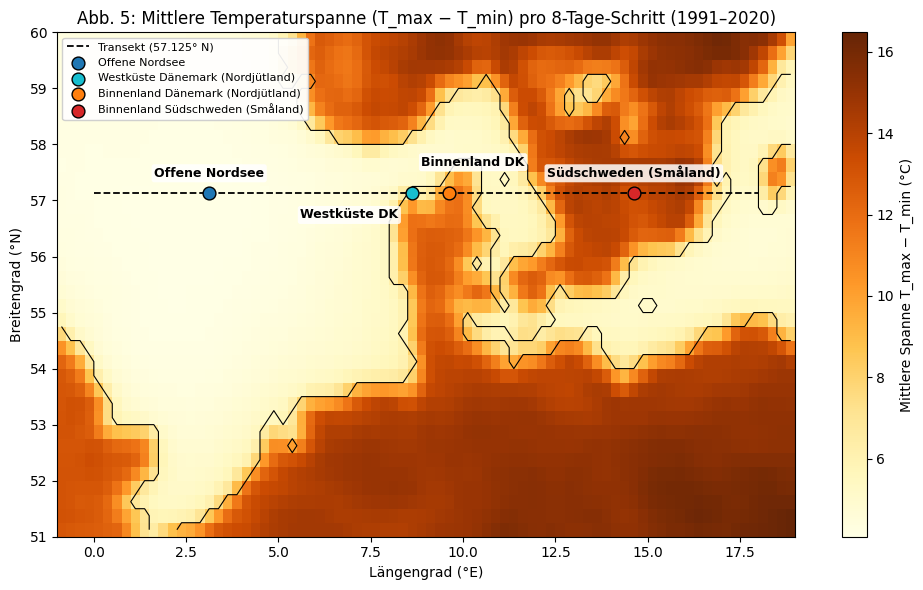

Mittlere 8-Tage-Temperaturspanne (T_max − T_min, 1991–2020):
  - Offene Nordsee          :  4.10 °C
  - Westküste DK            :  7.12 °C
  - Binnenland DK           : 11.27 °C
  - Südschweden (Småland)   : 13.10 °C


In [25]:
# 1. Für jeden 8-Tage-Zeitschritt die Differenz zwischen Höchst- und Tiefsttemperatur berechnen
#    und über alle Zeitschritte von 1991–2020 mitteln
spanne_mittel = (t_max - t_min).mean('time')

# 2. Karte der mittleren Spanne (Abb. 5) erstellen
fig, ax = plt.subplots(figsize=(10, 6))
spanne_mittel.plot(ax=ax, cmap='YlOrBr', cbar_kwargs={'label': 'Mittlere Spanne T_max − T_min (°C)'})
zeichne_kueste(ax)

# Gestrichelte Transekt-Linie entlang 57.125° N
ax.plot(
    [0, 18],
    [transekt_lat, transekt_lat],
    color='black',
    linestyle='--',
    linewidth=1.3,
    label=f'Transekt ({transekt_lat:.3f}° N)',
)

# Alle vier Vergleichsorte markieren und beschriften
for name, info in orte.items():
    ax.scatter(
        info['lon'],
        info['lat'],
        color=info['color'],
        edgecolor='black',
        s=85,
        zorder=5,
        label=name,
    )
    ax.annotate(
        info['kurz'],
        xy=(info['lon'], info['lat']),
        xytext=info['offset'],
        textcoords='offset points',
        ha=info['ha'],
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.85, ec='none'),
        zorder=6,
    )

ax.set_title('Abb. 5: Mittlere Temperaturspanne (T_max − T_min) pro 8-Tage-Schritt (1991–2020)')
ax.set_xlabel('Längengrad (°E)')
ax.set_ylabel('Breitengrad (°N)')
ax.legend(loc='upper left', fontsize=8, framealpha=0.92)
plt.tight_layout()
plt.show()

# Mittlere kurzfristige Spanne an den 4 Vergleichsorten ausgeben
print('Mittlere 8-Tage-Temperaturspanne (T_max − T_min, 1991–2020):')
for name, info in orte.items():
    sp_wert = float(spanne_mittel.sel(lat=info['lat'], lon=info['lon'], method='nearest'))
    kurz = info['kurz']
    print(f'  - {kurz:24s}: {sp_wert:5.2f} °C')

### Ergebnisse & Beobachtungen (Abb. 5)

- **Scharfe Küstengrenze:** Auch auf kurzer 8-Tage-Zeitskala trennen die Küstenlinien zwei völlig unterschiedliche Regime: Über Nordsee, Kattegat und Ostsee bleibt die Spanne `T_max − T_min` fast einheitlich niedrig (~4–6 °C, hellgelb), während sie direkt über Land stark ansteigt (~11–16 °C, orange bis dunkelbraun).
- **Messwerte entlang `57,125° N` (1991–2020):**
  - `Offene Nordsee`: **4,10 °C**
  - `Westküste DK`: **7,12 °C** (deutlich gedämpfte Übergangszone direkt an der Küste)
  - `Binnenland DK`: **11,27 °C** (nahezu das Dreifache der offenen Nordsee)
  - `Südschweden (Småland)`: **13,10 °C** (über das Dreifache der offenen Nordsee)
- **Fazit:** Der stabilisierende Einfluss der Nordsee wirkt nicht nur im Jahresgang (Abb. 1–4), sondern dämpft auch kurzfristige Temperatursprünge zwischen Höchst- und Tiefstwerten erheblich ab.